# Highway Networks na CIFAR-10 (PyTorch)

Implementacja na podstawie: R. K. Srivastava, K. Greff, J. Schmidhuber, **„Highway Networks”**, arXiv:1505.00387 (2015), https://arxiv.org/abs/1505.00387



In [ ]:
# domyślnie pełny trening, konfiguracja eksperymentu MNIST (Fig. 1), zapis na Drive
import time, random, copy, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
``
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

device = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cudnn.benchmark = True

if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    print("GPU:", torch.cuda.get_device_name(0))

print("Device:", device, "| PyTorch:", torch.__version__)

# ==================================
# WYBÓR TRYBU
# ==================================

FAST_MODE = False  # True = szybki test kodu, False = pełny trening do raportu
USE_DRIVE = True            # dane, wyniki i checkpointy na Google Drive (działa tylko w Colabie)
LOAD_SAVED_RESULTS = True   # jeśli wyniki z poprzedniej sesji są zapisane, wczytaj je zamiast trenować

if FAST_MODE:
    EPOCHS_MAIN = 8
    TRAIN_SIZE = 10_000
    VAL_SIZE = 2_000
    WIDTHS = (32, 64, 128)
    LAYERS_PER_STAGE = 3

    FC_EPOCHS = 5
    FC_LRS = [0.03]
    FC_GATE_BIASES = [-2.0]

else:
    EPOCHS_MAIN = 40
    TRAIN_SIZE = 45_000
    VAL_SIZE = 5_000
    WIDTHS = (64, 128, 256)
    LAYERS_PER_STAGE = 5

    FC_EPOCHS = 10
    FC_LRS = [0.01, 0.03]
    FC_GATE_BIASES = [-4.0]
    FC_DEPTHS = [10, 50, 100]

# Eksperyment z Fig. 1 artykułu: MNIST, sieci w pełni połączone
FC_DEPTHS = [10, 50, 100]
FC_WIDTH_HIGHWAY = 50   # jak w artykule
FC_WIDTH_PLAIN = 71     # jak w artykule -> prawie ta sama liczba parametrów na warstwę
FC_BATCH_SIZE = 128
MNIST_VAL_SIZE = 10_000

BATCH_SIZE = 128
NUM_WORKERS = 2


print("FAST_MODE:", FAST_MODE)
print("Train size:", TRAIN_SIZE)
print("Validation size:", VAL_SIZE)
print("Main epochs:", EPOCHS_MAIN)
print("MNIST FC epochs:", FC_EPOCHS)

GPU: Tesla T4
Device: cuda | PyTorch: 2.11.0+cu130
FAST_MODE: False
Train size: 45000
Validation size: 5000
Main epochs: 40
MNIST FC epochs: 20


## 0. Google Drive — zapis między sesjami


In [4]:
# Google Drive: dane, wyniki i checkpointy przetrwają między sesjami Colaba
import shutil

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATASET_DIRS = ["cifar-10-batches-py", "MNIST"]   # rozpakowane zbiory (bez archiwów .tar.gz)

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/highway_project")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    OUT = DRIVE_DIR / "highway_results"
    # Przywracanie danych z Drive -> lokalny dysk Colaba
    for sub in DATASET_DIRS:
        src, dst = DRIVE_DIR / "data" / sub, Path("./data") / sub
        if src.exists() and not dst.exists():
            print(f"Kopiuję {sub} z Drive...")
            shutil.copytree(src, dst)
else:
    DRIVE_DIR = None
    OUT = Path("highway_results")
OUT.mkdir(parents=True, exist_ok=True)


def backup_data_to_drive():
    """Kopiuje pobrane zbiory na Drive, jeśli jeszcze ich tam nie ma (jednorazowo)."""
    if DRIVE_DIR is None:
        return
    for sub in DATASET_DIRS:
        src, dst = Path("./data") / sub, DRIVE_DIR / "data" / sub
        if src.exists() and not dst.exists():
            print(f"Zapisuję {sub} na Drive (jednorazowo)...")
            shutil.copytree(src, dst)


MODE_TAG = "fast" if FAST_MODE else "full"
CKPT = OUT / f"highway_best_{MODE_TAG}.pt"
HIST_CSV = OUT / f"main_history_{MODE_TAG}.csv"
FC_ALL_CSV = OUT / f"fc_depth_all_runs_{MODE_TAG}.csv"
FC_RUNS_JSON = OUT / f"fc_runs_{MODE_TAG}.json"
print("Wyniki zapisywane w:", OUT.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Wyniki zapisywane w: /content/drive/MyDrive/highway_project/highway_results


## 1. Dane — train / validation / test


In [5]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

eval_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

# ==================================
# POBIERANIE DANYCH
# ==================================

full_train_aug = torchvision.datasets.CIFAR10(
    "./data",
    train=True,
    download=True,
    transform=train_tf
)

full_train_eval = torchvision.datasets.CIFAR10(
    "./data",
    train=True,
    download=False,
    transform=eval_tf
)

test_set = torchvision.datasets.CIFAR10(
    "./data",
    train=False,
    download=True,
    transform=eval_tf
)

# ==================================
# PODZIAŁ DANYCH
# ==================================

indices = torch.randperm(
    len(full_train_aug),
    generator=torch.Generator().manual_seed(SEED)
).tolist()

# Najpierw wydzielamy stałe pule train/validation
train_pool = indices[:45000]
val_pool = indices[45000:]

# Następnie ograniczamy ich rozmiar
train_ids = train_pool[:TRAIN_SIZE]
val_ids = val_pool[:VAL_SIZE]

train_set = Subset(full_train_aug, train_ids)
val_set = Subset(full_train_eval, val_ids)

# ==================================
# DATALOADERS
# ==================================

pin = device == "cuda"

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin,
    drop_last=False
)

val_loader = DataLoader(
    val_set,
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin
)

test_loader = DataLoader(
    test_set,
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin
)

CLASSES = test_set.classes

print("Train:", len(train_set))
print("Validation:", len(val_set))
print("Test:", len(test_set))

backup_data_to_drive()   # kopia CIFAR-10 na Drive (tylko za pierwszym razem)

100%|██████████| 170M/170M [28:27<00:00, 99.8kB/s]


Train: 45000
Validation: 5000
Test: 10000
Zapisuję cifar-10-batches-py na Drive (jednorazowo)...


## 2. Model
### Warstwa highway (konwolucyjna)

In [6]:
class HighwayConv2d(nn.Module):
    """Konwolucyjna warstwa highway: y = H(x)*T(x) + x*(1 - T(x))."""

    def __init__(self, ch, kernel_size=3, gate_bias=-2.0, use_bn=True):
        super().__init__()
        p = kernel_size // 2
        self.H = nn.Conv2d(ch, ch, kernel_size, padding=p, bias=not use_bn)
        self.bn = nn.BatchNorm2d(ch) if use_bn else nn.Identity()
        self.T = nn.Conv2d(ch, ch, kernel_size, padding=p, bias=True)
        nn.init.kaiming_normal_(self.H.weight, nonlinearity="relu")
        nn.init.constant_(self.T.bias, gate_bias)   # ujemny bias -> start w trybie "carry"
        self.record = False
        self.gate_stats = []

    def forward(self, x):
        h = F.relu(self.bn(self.H(x)))
        t = torch.sigmoid(self.T(x))
        if self.record:
            # średnia po pozycjach przestrzennych -> (batch, kanały)
            self.gate_stats.append(t.mean(dim=(2, 3)).detach().float().cpu())
        return x + t * (h - x)          # == h*t + x*(1-t)


class PlainConv2d(nn.Module):
    """Zwykła warstwa: y = ReLU(BN(conv(x))). Do porównań."""

    def __init__(self, ch, kernel_size=3, use_bn=True, **_):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, kernel_size, padding=kernel_size // 2, bias=not use_bn)
        self.bn = nn.BatchNorm2d(ch) if use_bn else nn.Identity()
        nn.init.kaiming_normal_(self.conv.weight, nonlinearity="relu")

    def forward(self, x):
        return F.relu(self.bn(self.conv(x)))


def conv_bn_relu(cin, cout, k, use_bn=True):
    layers = [nn.Conv2d(cin, cout, k, padding=k // 2, bias=not use_bn)]
    if use_bn:
        layers.append(nn.BatchNorm2d(cout))
    layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)

### Sieć główna — 15 bloków Highway


In [7]:
class HighwayNet(nn.Module):
    def __init__(self, block="highway", widths=(64, 128, 256), layers_per_stage=5,
                 use_bn=True, gate_bias=-2.0, num_classes=10):
        super().__init__()
        Block = HighwayConv2d if block == "highway" else PlainConv2d
        self.stem = conv_bn_relu(3, widths[0], 3, use_bn)
        stages, prev = [], widths[0]
        for i, w in enumerate(widths):
            mods = []
            if i > 0:   # przejście: zmiana rozdzielczości i liczby kanałów
                mods += [nn.MaxPool2d(2), conv_bn_relu(prev, w, 1, use_bn)]
            mods += [Block(w, gate_bias=gate_bias, use_bn=use_bn) for _ in range(layers_per_stage)]
            stages.append(nn.Sequential(*mods))
            prev = w
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(prev, num_classes))

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))

    def highway_layers(self):
        return [m for m in self.modules() if isinstance(m, HighwayConv2d)]


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = HighwayNet()
print("HighwayNet params: %.2fM" % (count_params(_m) / 1e6))
print("output shape:", _m(torch.randn(2, 3, 32, 32)).shape)
del _m

HighwayNet params: 7.79M
output shape: torch.Size([2, 10])


## 3. Trening


In [8]:

amp_enabled = device == 'cuda'

def run_epoch(model, loader, opt=None, sched=None, scaler=None, clip=5.0, amp=None):
    train = opt is not None
    use_amp = amp_enabled if amp is None else (amp and amp_enabled)
    model.train(train)
    loss_sum = correct = n = 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = F.cross_entropy(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    nn.utils.clip_grad_norm_(model.parameters(), clip)
                    scaler.step(opt)
                    scaler.update()
                else:
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), clip)
                    opt.step()
                if sched is not None:
                    sched.step()
        loss_sum += loss.detach().item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n


def fit(model, epochs, lr=0.1, wd=5e-4, onecycle=True, verbose=True,
        checkpoint_path=None, seed=None, train_dl=None, val_dl=None, amp=True):
    if seed is not None:
        seed_everything(seed)
    if train_dl is None:
        train_dl = train_loader
    if val_dl is None:
        val_dl = val_loader
    use_amp = amp and amp_enabled
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    sched = (torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                  steps_per_epoch=len(train_dl)) if onecycle else None)
    scaler = torch.amp.GradScaler('cuda', enabled=True) if use_amp else None
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    best_val_acc, best_ep = -1., 0
    best_weights = None
    for ep in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_dl, opt, sched, scaler, amp=use_amp)
        val_loss, val_acc = run_epoch(model, val_dl, amp=use_amp)
        for name, value in zip(hist, (train_loss, train_acc, val_loss, val_acc)):
            hist[name].append(value)
        if val_acc > best_val_acc:
            best_val_acc, best_ep = val_acc, ep
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if checkpoint_path is not None:
                torch.save({'epoch': ep, 'model_state': best_weights,
                            'optimizer_state': opt.state_dict(),
                            'scheduler_state': sched.state_dict() if sched else None,
                            'val_acc': val_acc, 'history': hist,
                            'seed': SEED if seed is None else seed}, checkpoint_path)
        if verbose:
            print(f'ep {ep:3d} | train {train_loss:.3f}/{train_acc:.2%} | '
                  f'val {val_loss:.3f}/{val_acc:.2%} | {time.time()-start:.0f}s')
    # Dalsze analizy używają najlepszego modelu, nie końcowego.
    model.load_state_dict(best_weights)
    hist['best_epoch'] = best_ep
    hist['best_val_acc'] = best_val_acc
    return hist

In [9]:
# jeśli model z poprzedniej sesji jest zapisany, wczytujemy go zamiast trenować
seed_everything(SEED)
model = HighwayNet(
    block="highway",
    widths=WIDTHS,
    layers_per_stage=LAYERS_PER_STAGE,
    use_bn=True,
    gate_bias=-2.0
)
print(f'Parametry modelu: {count_params(model):,}')

if LOAD_SAVED_RESULTS and CKPT.exists() and HIST_CSV.exists():
    ckpt = torch.load(CKPT, map_location='cpu', weights_only=True)
    model.load_state_dict(ckpt['model_state'])
    model.to(device)
    hist_main = pd.read_csv(HIST_CSV).to_dict('list')
    hist_main['best_epoch'], hist_main['best_val_acc'] = ckpt['epoch'], ckpt['val_acc']
    print(f'Wczytano zapisany model ({CKPT.name}), trening pominięty. '
          'Ustaw LOAD_SAVED_RESULTS = False, aby trenować od nowa.')
else:
    hist_main = fit(model, EPOCHS_MAIN, lr=0.1, checkpoint_path=CKPT)
    pd.DataFrame({k: v for k, v in hist_main.items() if isinstance(v, list)}).to_csv(HIST_CSV, index=False)

print(f"Najlepsza walidacja: {hist_main['best_val_acc']:.2%} (epoka {hist_main['best_epoch']})")

Parametry modelu: 7,794,314
ep   1 | train 1.829/32.30% | val 1.583/41.66% | 42s
ep   2 | train 1.333/51.49% | val 1.534/48.38% | 36s
ep   3 | train 1.003/63.98% | val 1.139/62.34% | 39s
ep   4 | train 0.813/71.14% | val 1.077/64.56% | 40s
ep   5 | train 0.663/76.96% | val 0.954/71.14% | 39s
ep   6 | train 0.574/80.16% | val 1.037/70.06% | 40s
ep   7 | train 0.512/82.59% | val 1.607/61.52% | 39s
ep   8 | train 0.464/84.16% | val 0.750/76.94% | 39s
ep   9 | train 0.435/85.22% | val 0.696/76.92% | 39s
ep  10 | train 0.406/86.03% | val 0.564/80.80% | 39s
ep  11 | train 0.384/86.93% | val 0.754/75.90% | 39s
ep  12 | train 0.366/87.55% | val 0.613/80.06% | 39s
ep  13 | train 0.351/88.03% | val 0.716/77.72% | 39s
ep  14 | train 0.336/88.54% | val 0.481/84.02% | 39s
ep  15 | train 0.329/88.92% | val 0.508/83.30% | 39s
ep  16 | train 0.313/89.24% | val 0.547/82.22% | 39s
ep  17 | train 0.312/89.17% | val 0.755/76.34% | 39s
ep  18 | train 0.295/89.88% | val 0.541/82.80% | 39s
ep  19 | train 0.2

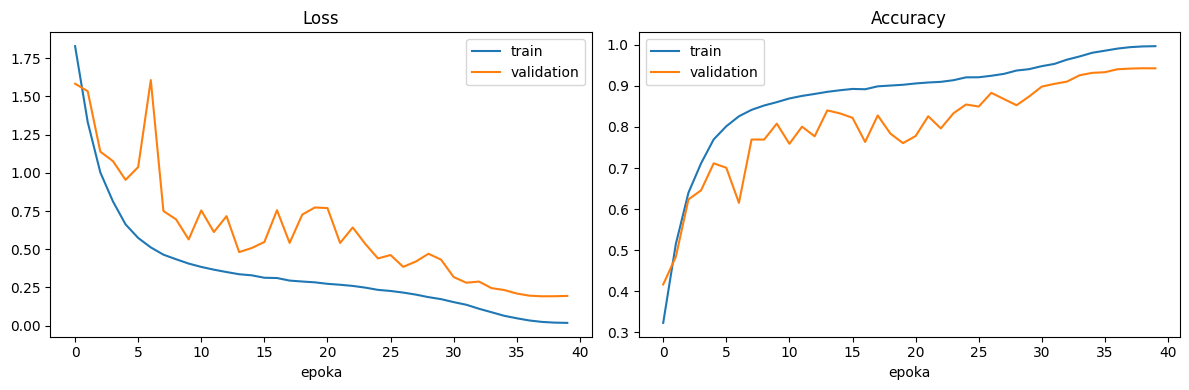

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_main['train_loss'], label='train')
ax[0].plot(hist_main['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoka'); ax[0].legend()
ax[1].plot(hist_main['train_acc'], label='train')
ax[1].plot(hist_main['val_acc'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoka'); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/'training_curves.png', dpi=150); plt.show()

In [11]:
# Analiza walidacyjna
@torch.no_grad()
def per_class_accuracy(model, loader):
    model.eval()
    correct, total = torch.zeros(10), torch.zeros(10)
    for x, y in loader:
        pred = model(x.to(device)).argmax(1).cpu()
        for c in range(10):
            mask = y == c
            correct[c] += (pred[mask] == c).sum()
            total[c] += mask.sum()
    return correct / total.clamp_min(1)

for c, a in zip(CLASSES, per_class_accuracy(model, val_loader)):
    print(f'{c:12s} {a:.2%}')

airplane     95.29%
automobile   96.29%
bird         91.17%
cat          89.17%
deer         95.54%
dog          88.13%
frog         96.45%
horse        94.60%
ship         97.82%
truck        98.40%


## 4. Eksperyment głębokości: Plain vs Highway (odpowiednik Fig. 1)

In [12]:
# MNIST do eksperymentu z Fig. 1 (mały zbiór, ok. 11 MB).

mnist_train_full = torchvision.datasets.MNIST("./data", train=True, download=True)

def mnist_tensors(ds):
    x = ds.data.float().div(255.).sub(0.1307).div(0.3081).view(len(ds), -1)  # 28x28 -> wektor 784
    return x, ds.targets.clone()

Xm, Ym = mnist_tensors(mnist_train_full)
perm = torch.randperm(len(Xm), generator=torch.Generator().manual_seed(SEED))
mnist_tr, mnist_va = perm[:-MNIST_VAL_SIZE], perm[-MNIST_VAL_SIZE:]


class TensorLoader:
    """Minimalny odpowiednik DataLoadera dla danych trzymanych w całości na GPU."""

    def __init__(self, x, y, batch_size, shuffle):
        self.x, self.y = x.to(device), y.to(device)
        self.batch_size, self.shuffle = batch_size, shuffle

    def __len__(self):
        return (len(self.x) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device)
        for i in range(0, n, self.batch_size):
            j = idx[i:i + self.batch_size]
            yield self.x[j], self.y[j]


mnist_train_loader = TensorLoader(Xm[mnist_tr], Ym[mnist_tr], FC_BATCH_SIZE, shuffle=True)
mnist_val_loader = TensorLoader(Xm[mnist_va], Ym[mnist_va], 1000, shuffle=False)
print("MNIST train:", len(mnist_tr), "| validation:", len(mnist_va))

backup_data_to_drive()   # kopia MNIST na Drive (tylko za pierwszym razem)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 488kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.69MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.90MB/s]


MNIST train: 50000 | validation: 10000
Zapisuję MNIST na Drive (jednorazowo)...


In [13]:
#  Warstwy w pełni połączone: highway i plain, oraz sieć z Fig. 1
class HighwayLinear(nn.Module):
    """W pełni połączona warstwa highway: y = H(x)*T(x) + x*(1 - T(x))."""

    def __init__(self, dim, gate_bias=-2.0):
        super().__init__()
        self.H = nn.Linear(dim, dim)
        self.T = nn.Linear(dim, dim)
        nn.init.kaiming_normal_(self.H.weight, nonlinearity="relu")
        nn.init.zeros_(self.H.bias)
        nn.init.constant_(self.T.bias, gate_bias)   # ujemny bias -> start w trybie "carry"

    def forward(self, x):
        h = F.relu(self.H(x))
        t = torch.sigmoid(self.T(x))
        return x + t * (h - x)


class PlainLinear(nn.Module):
    """Zwykła warstwa w pełni połączona: y = ReLU(Wx + b)."""

    def __init__(self, dim, **_):
        super().__init__()
        self.fc = nn.Linear(dim, dim)
        nn.init.kaiming_normal_(self.fc.weight, nonlinearity="relu")
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        return F.relu(self.fc(x))


class FCDepthNet(nn.Module):
    """Sieć z sekcji 3.1: zwykła warstwa 784 -> szerokość, potem (depth - 1) warstw plain/highway, softmax."""

    def __init__(self, depth, block="highway", gate_bias=-2.0, in_dim=784, num_classes=10):
        super().__init__()
        width = FC_WIDTH_HIGHWAY if block == "highway" else FC_WIDTH_PLAIN
        Block = HighwayLinear if block == "highway" else PlainLinear
        self.inp = nn.Linear(in_dim, width)
        nn.init.kaiming_normal_(self.inp.weight, nonlinearity="relu")
        nn.init.zeros_(self.inp.bias)
        self.body = nn.Sequential(*[Block(width, gate_bias=gate_bias) for _ in range(depth - 1)])
        self.head = nn.Linear(width, num_classes)

    def forward(self, x):
        return self.head(self.body(F.relu(self.inp(x))))


for blk in ["plain", "highway"]:
    print(f"{blk:8s} 100 warstw: {count_params(FCDepthNet(100, blk)):,} parametrów")

plain    100 warstw: 562,543 parametrów
highway  100 warstw: 544,660 parametrów


In [ ]:
# Ograniczona siatka hiperparametrów (ze względu na czas obliczeń).
FC_DEPTHS = [10, 50]
FC_LRS = [0.01, 0.03]
FC_GATE_BIASES = [-4.0]
FC_EPOCHS = 10
print(FC_DEPTHS, FC_LRS, FC_GATE_BIASES, FC_EPOCHS)

[10, 50] [0.01, 0.03] [-4.0] 10


In [21]:
#plain vs highway na MNIST
# Jeśli wyniki z poprzedniej sesji są zapisane, wczytujemy je zamiast trenować od nowa.
if LOAD_SAVED_RESULTS and FC_ALL_CSV.exists() and FC_RUNS_JSON.exists():
    fc_df = pd.read_csv(FC_ALL_CSV)
    fc_runs = json.loads(FC_RUNS_JSON.read_text())
    print(f"Wczytano zapisane wyniki ({len(fc_runs)} przebiegów), trening pominięty. "
          "Ustaw LOAD_SAVED_RESULTS = False, aby trenować od nowa.")
else:
    fc_runs, summary = [], []
    for depth in FC_DEPTHS:
        for block in ["plain", "highway"]:
            gate_biases = FC_GATE_BIASES if block == "highway" else [None]
            for lr in FC_LRS:
                for gb in gate_biases:
                    seed_everything(SEED)
                    net = FCDepthNet(depth, block, gate_bias=-2.0 if gb is None else gb)
                    start = time.time()
                    hist = fit(net, FC_EPOCHS, lr=lr, wd=0., onecycle=False, verbose=False,
                               train_dl=mnist_train_loader, val_dl=mnist_val_loader, amp=False)
                    summary.append({"run": len(fc_runs), "block": block, "depth": depth, "lr": lr,
                                    "gate_bias": gb, "parameters": count_params(net),
                                    "final_train_loss": hist["train_loss"][-1],
                                    "best_val_acc": hist["best_val_acc"]})
                    fc_runs.append(hist)
                    print(f"{block:8s} depth={depth:3d} lr={lr:<5} gate_bias={gb} | "
                          f"train loss {hist['train_loss'][-1]:.4f} | "
                          f"val acc {hist['best_val_acc']:.2%} | {time.time() - start:.0f}s")
                    del net
                    if device == "cuda":
                        torch.cuda.empty_cache()

    fc_df = pd.DataFrame(summary)
    fc_df["final_train_loss"] = fc_df["final_train_loss"].fillna(np.inf)   # rozbiegnięte przebiegi na koniec
    fc_df.to_csv(FC_ALL_CSV, index=False)
    FC_RUNS_JSON.write_text(json.dumps(fc_runs))

# dla każdej pary (typ, głębokość) bierzemy najlepszy przebieg
best_df = (fc_df.loc[fc_df.groupby(["block", "depth"])["final_train_loss"].idxmin()]
           .sort_values(["depth", "block"]).reset_index(drop=True))
best_df.to_csv(OUT / f"fc_depth_best_{MODE_TAG}.csv", index=False)
display(best_df)

plain    depth= 10 lr=0.01  gate_bias=None | train loss 0.0452 | val acc 96.76% | 15s
plain    depth= 10 lr=0.03  gate_bias=None | train loss 0.0502 | val acc 97.23% | 14s
highway  depth= 10 lr=0.01  gate_bias=-4.0 | train loss 0.0405 | val acc 96.95% | 27s
highway  depth= 10 lr=0.03  gate_bias=-4.0 | train loss 0.0229 | val acc 96.87% | 28s
plain    depth= 50 lr=0.01  gate_bias=None | train loss 0.6440 | val acc 87.70% | 46s
plain    depth= 50 lr=0.03  gate_bias=None | train loss 0.9229 | val acc 75.28% | 47s
highway  depth= 50 lr=0.01  gate_bias=-4.0 | train loss 0.0430 | val acc 96.82% | 121s
highway  depth= 50 lr=0.03  gate_bias=-4.0 | train loss 0.0298 | val acc 96.87% | 123s


,run,block,depth,lr,gate_bias,parameters,final_train_loss,best_val_acc
0,3,highway,10,0.03,-4.0,85660,0.022875,0.9687
1,0,plain,10,0.01,NaN,102463,0.045232,0.9676
2,7,highway,50,0.03,-4.0,289660,0.029779,0.9687
3,4,plain,50,0.01,NaN,306943,0.644044,0.8770


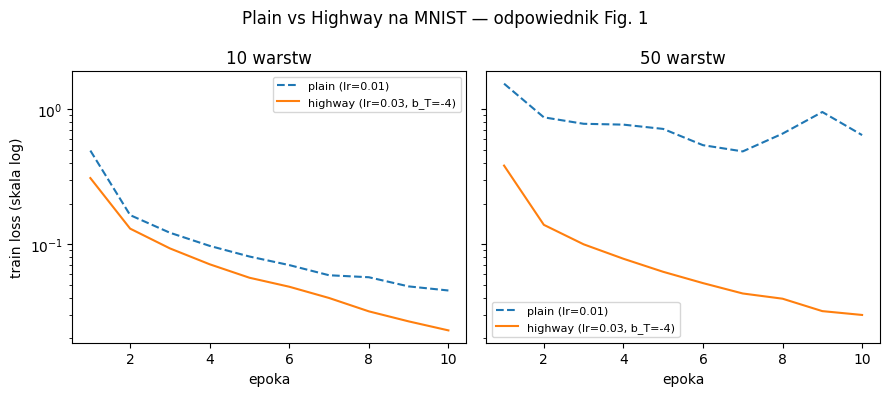

In [22]:
# train loss w kolejnych epokach, najlepszy przebieg dla każdej konfiguracji
fig, axes = plt.subplots(1, len(FC_DEPTHS), figsize=(4.5 * len(FC_DEPTHS), 4), sharey=True, squeeze=False)
for ax, depth in zip(axes[0], FC_DEPTHS):
    for block, style in [("plain", "--"), ("highway", "-")]:
        row = best_df[(best_df.block == block) & (best_df.depth == depth)].iloc[0]
        label = f"{block} (lr={row.lr}" + (f", b_T={row.gate_bias:g})" if block == "highway" else ")")
        ax.plot(range(1, FC_EPOCHS + 1), fc_runs[int(row.run)]["train_loss"], style, label=label)
    ax.set_yscale("log")
    ax.set_title(f"{depth} warstw")
    ax.set_xlabel("epoka")
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel("train loss (skala log)")
plt.suptitle("Plain vs Highway na MNIST — odpowiednik Fig. 1")
plt.tight_layout(); plt.savefig(OUT / "fc_depth_comparison.png", dpi=150); plt.show()

## 5 Końcowa ewaluacja na zbiorze testowym


FINAL TEST | loss=0.2146 | accuracy=93.84%
airplane    : 94.80%
automobile  : 96.10%
bird        : 91.10%
cat         : 87.10%
deer        : 96.50%
dog         : 89.10%
frog        : 96.30%
horse       : 94.30%
ship        : 96.70%
truck       : 96.30%


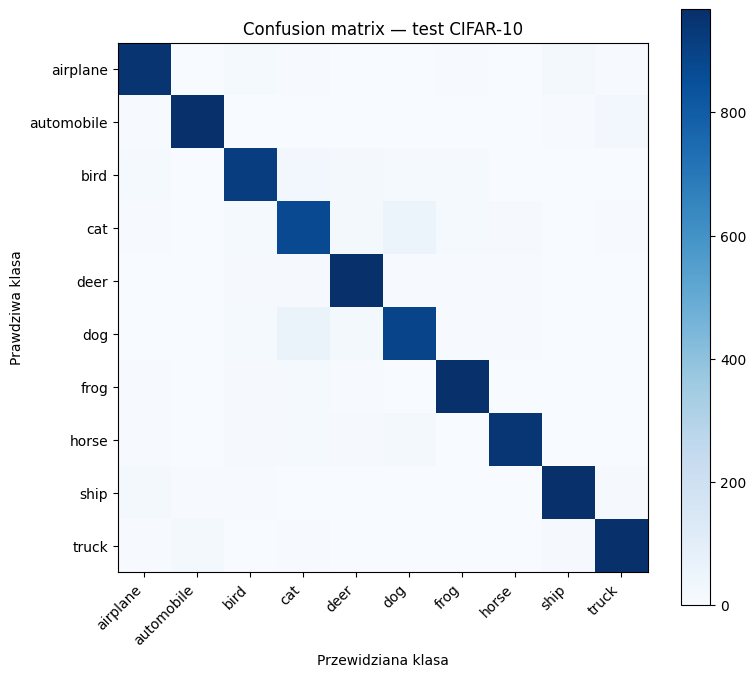

In [26]:
# Ponownie wczytujemy najlepszy checkpoint, aby uniknąć pomyłek.
checkpoint = torch.load(CKPT, map_location='cpu', weights_only=True)
model.load_state_dict(checkpoint['model_state'])
model.to(device)
test_loss, test_acc = run_epoch(model, test_loader)
print(f'FINAL TEST | loss={test_loss:.4f} | accuracy={test_acc:.2%}')
class_acc = per_class_accuracy(model, test_loader)
for cls, acc in zip(CLASSES, class_acc):
    print(f'{cls:12s}: {acc:.2%}')
(OUT/f'final_metrics_{MODE_TAG}.json').write_text(json.dumps({
    'test_loss': test_loss, 'test_accuracy': test_acc,
    'best_epoch': hist_main['best_epoch'], 'best_val_accuracy': hist_main['best_val_acc'],
    'class_accuracy': {c: float(a) for c,a in zip(CLASSES, class_acc)}
}, indent=2), encoding='utf-8')

cm = np.zeros((10,10), dtype=np.int64)
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        pred = model(images.to(device)).argmax(1).cpu().numpy()
        np.add.at(cm, (labels.numpy(), pred), 1)
fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right')
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel('Przewidziana klasa'); ax.set_ylabel('Prawdziwa klasa')
ax.set_title('Confusion matrix — test CIFAR-10')
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png', dpi=150); plt.show()
